# Evaluación económica del Parque Solar Villanueva

Este cuaderno reproduce los cálculos del ejercicio de la Unidad 1: factor de planta, degradación, valores presentes, LCOE, ingreso implícito, VPN, punto de equilibrio y sensibilidad. Los datos marcados como **[1]** proceden de la referencia pública del proyecto; los demás son **[Supuesto]** del ejercicio académico.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.options.display.float_format = lambda valor: f'{valor:,.2f}'

## 1. Datos públicos y supuestos

Se utilizan pesos mexicanos constantes y una tasa de descuento real. La inversión se registra completa en $t=0$; por tanto, el modelo representa un análisis del proyecto antes de impuestos y sin deuda.

In [2]:
# Datos públicos [1]
capacidad_mw = 363.0
inversion_inicial = 8_720_000_000.0  # MXN
energia_ano_1 = 972_915.0             # MWh
cel_anuales = 975_915.0               # CEL/año
ingreso_ano_1 = 597_503_346.0         # MXN; precio ofertado publicado

# Supuestos del ejercicio
horas_ano = 8_760
periodo = 20
tasa_descuento = 0.08
degradacion = 0.005
opex_porcentaje = 0.015
reposicion_porcentaje = 0.05
ano_reposicion = 12
desmantelamiento_porcentaje = 0.02
valor_residual = 0.0

opex_anual = inversion_inicial * opex_porcentaje
costo_reposicion = inversion_inicial * reposicion_porcentaje
costo_desmantelamiento = inversion_inicial * desmantelamiento_porcentaje

datos = pd.DataFrame({
    'Dato': ['Capacidad', 'Inversión inicial', 'Energía del año 1',
             'Ingreso del año 1', 'Tasa de descuento', 'Degradación',
             'OPEX anual', 'Reposición en año 12', 'Desmantelamiento en año 20'],
    'Valor': [capacidad_mw, inversion_inicial, energia_ano_1, ingreso_ano_1,
              tasa_descuento, degradacion, opex_anual, costo_reposicion,
              costo_desmantelamiento],
    'Procedencia': ['[1]', '[1]', '[1]', '[1] y [Supuesto]', '[Supuesto]',
                    '[Supuesto]', '[Supuesto]', '[Supuesto]', '[Supuesto]']
})
display(datos)

,Dato,Valor,Procedencia
0,Capacidad,363.00,[1]
1,Inversión inicial,"8,720,000,000.00",[1]
2,Energía del año 1,"972,915.00",[1]
3,Ingreso del año 1,"597,503,346.00",[1] y [Supuesto]
4,Tasa de descuento,0.08,[Supuesto]
5,Degradación,0.01,[Supuesto]
6,OPEX anual,"130,800,000.00",[Supuesto]
7,Reposición en año 12,"436,000,000.00",[Supuesto]
8,Desmantelamiento en año 20,"174,400,000.00",[Supuesto]


## 2. Factor de planta implícito

$$FC=\frac{E_{anual}}{P_{instalada}\,h_{anual}}$$

In [3]:
factor_planta = energia_ano_1 / (capacidad_mw * horas_ano)
print(f'FC = {energia_ano_1:,.0f} / ({capacidad_mw:,.0f} × {horas_ano:,})')
print(f'Factor de planta implícito = {factor_planta:.5f} = {factor_planta:.2%}')
assert np.isclose(factor_planta, 0.30596, atol=1e-5)

FC = 972,915 / (363 × 8,760)
Factor de planta implícito = 0.30596 = 30.60%


## 3. Producción anual y degradación

$$E_t=E_1(1-d)^{t-1}$$

In [4]:
anos = np.arange(1, periodo + 1)
energia = energia_ano_1 * (1 - degradacion) ** (anos - 1)
energia_acumulada = energia.sum()
reduccion_ano_20 = 1 - energia[-1] / energia[0]

print(f'Energía del año 20 = {energia[-1]:,.2f} MWh')
print(f'Energía acumulada = {energia_acumulada:,.2f} MWh')
print(f'Reducción respecto al año 1 = {reduccion_ano_20:.2%}')
assert np.isclose(energia[-1], 884_531.76, atol=0.01)
assert np.isclose(energia_acumulada, 18_561_178.92, atol=0.01)

Energía del año 20 = 884,531.76 MWh
Energía acumulada = 18,561,178.92 MWh
Reducción respecto al año 1 = 9.08%


## 4. Valor presente de la energía

$$VP_E=\sum_{t=1}^{20}\frac{E_t}{(1+r)^t}$$

El descuento aplicado a la energía no representa una pérdida física; permite construir el denominador económico del LCOE de manera consistente.

In [5]:
factores_descuento = 1 / (1 + tasa_descuento) ** anos
energia_descontada = energia * factores_descuento
vp_energia = energia_descontada.sum()

print(f'Valor presente de la energía = {vp_energia:,.2f} MWh')
assert np.isclose(vp_energia, 9_224_578.46, atol=0.01)

Valor presente de la energía = 9,224,578.46 MWh


## 5. Valor presente de los costos

$$VP_C=I_0+VP_{OPEX}+VP_{rep}+VP_{des}$$

In [6]:
vp_opex = np.sum(opex_anual * factores_descuento)
vp_reposicion = costo_reposicion / (1 + tasa_descuento) ** ano_reposicion
vp_desmantelamiento = costo_desmantelamiento / (1 + tasa_descuento) ** periodo
vp_costos = inversion_inicial + vp_opex + vp_reposicion + vp_desmantelamiento - valor_residual / (1 + tasa_descuento) ** periodo

componentes_costos = pd.Series({
    'Inversión inicial': inversion_inicial,
    'VP del OPEX': vp_opex,
    'VP de la reposición': vp_reposicion,
    'VP del desmantelamiento': vp_desmantelamiento,
    'VP total de los costos': vp_costos,
}, name='MXN')
display(componentes_costos.to_frame())
assert np.isclose(vp_opex, 1_284_213_680.89, atol=0.01)
assert np.isclose(vp_reposicion, 173_141_598.77, atol=0.01)
assert np.isclose(vp_desmantelamiento, 37_417_207.37, atol=0.01)
assert np.isclose(vp_costos, 10_214_772_487.04, atol=0.02)

,MXN
Inversión inicial,"8,720,000,000.00"
VP del OPEX,"1,284,213,680.89"
VP de la reposición,"173,141,598.77"
VP del desmantelamiento,"37,417,207.37"
VP total de los costos,"10,214,772,487.04"


## 6. Costo nivelado de la energía

$$LCOE=\frac{VP_C}{VP_E}$$

In [7]:
lcoe_mxn_mwh = vp_costos / vp_energia
lcoe_mxn_kwh = lcoe_mxn_mwh / 1_000

print(f'LCOE = {lcoe_mxn_mwh:,.2f} MXN/MWh')
print(f'LCOE = {lcoe_mxn_kwh:.5f} MXN/kWh')
assert np.isclose(lcoe_mxn_kwh, 1.10734, atol=1e-5)

LCOE = 1,107.34 MXN/MWh
LCOE = 1.10734 MXN/kWh


## 7. Ingreso unitario e ingresos actualizados

El precio publicado se trata como ingreso conjunto de energía y CEL durante el primer año.

$$p_1=\frac{R_1}{E_1},\qquad R_t=R_1(1-d)^{t-1}$$

In [8]:
ingreso_unitario_mxn_mwh = ingreso_ano_1 / energia_ano_1
ingreso_unitario_mxn_kwh = ingreso_unitario_mxn_mwh / 1_000
ingresos = ingreso_ano_1 * (1 - degradacion) ** (anos - 1)
ingresos_descontados = ingresos * factores_descuento
vp_ingresos = ingresos_descontados.sum()

print(f'Ingreso unitario = {ingreso_unitario_mxn_mwh:,.2f} MXN/MWh')
print(f'Ingreso unitario = {ingreso_unitario_mxn_kwh:.5f} MXN/kWh')
print(f'Ingreso del año 20 = {ingresos[-1]:,.2f} MXN')
print(f'Valor presente de los ingresos = {vp_ingresos:,.2f} MXN')
assert np.isclose(ingreso_unitario_mxn_kwh, 0.61414, atol=1e-5)
assert np.isclose(ingresos[-1], 543_223_908.33, atol=0.01)
assert np.isclose(vp_ingresos, 5_665_157_280.32, atol=0.02)

Ingreso unitario = 614.14 MXN/MWh
Ingreso unitario = 0.61414 MXN/kWh
Ingreso del año 20 = 543,223,908.33 MXN
Valor presente de los ingresos = 5,665,157,280.32 MXN


## 8. Valor presente neto y punto de equilibrio

$$VPN=VP_R-VP_C$$

In [9]:
vpn = vp_ingresos - vp_costos
ingreso_equilibrio_ano_1 = lcoe_mxn_mwh * energia_ano_1
aumento_requerido = lcoe_mxn_mwh / ingreso_unitario_mxn_mwh - 1
cobertura_costos = vp_ingresos / vp_costos

print(f'VPN = {vpn:,.2f} MXN')
print(f'Ingreso de equilibrio del año 1 = {ingreso_equilibrio_ano_1:,.2f} MXN')
print(f'Aumento requerido del ingreso unitario = {aumento_requerido:.2%}')
print(f'Proporción del costo actualizado cubierta = {cobertura_costos:.2%}')
assert np.isclose(vpn, -4_549_615_206.72, atol=0.02)
assert np.isclose(ingreso_equilibrio_ano_1, 1_077_350_625.52, atol=0.02)
assert np.isclose(aumento_requerido, 0.8031, atol=1e-4)
assert np.isclose(cobertura_costos, 0.5546, atol=1e-4)

VPN = -4,549,615,206.72 MXN
Ingreso de equilibrio del año 1 = 1,077,350,625.52 MXN
Aumento requerido del ingreso unitario = 80.31%
Proporción del costo actualizado cubierta = 55.46%


## 9. Tabla anual del modelo

La tabla permite revisar cada flujo antes y después del descuento. La inversión inicial ocurre en el año 0 y, por ello, se presenta por separado.

In [10]:
reposicion_anual = np.where(anos == ano_reposicion, costo_reposicion, 0.0)
desmantelamiento_anual = np.where(anos == periodo, costo_desmantelamiento, 0.0)
costos_anuales = opex_anual + reposicion_anual + desmantelamiento_anual
flujo_neto = ingresos - costos_anuales

tabla_anual = pd.DataFrame({
    'Año': anos,
    'Energía (MWh)': energia,
    'Energía descontada (MWh)': energia_descontada,
    'Ingresos (MXN)': ingresos,
    'OPEX (MXN)': np.full(periodo, opex_anual),
    'Reposición (MXN)': reposicion_anual,
    'Desmantelamiento (MXN)': desmantelamiento_anual,
    'Flujo neto (MXN)': flujo_neto,
    'Flujo neto descontado (MXN)': flujo_neto * factores_descuento,
})
display(tabla_anual)

,Año,Energía (MWh),Energía descontada (MWh),Ingresos (MXN),OPEX (MXN),Reposición (MXN),Desmantelamiento (MXN),Flujo neto (MXN),Flujo neto descontado (MXN)
0,1,"972,915.00","900,847.22","597,503,346.00","130,800,000.00",0.00,0.00,"466,703,346.00","432,132,727.78"
1,2,"968,050.43","829,947.21","594,515,829.27","130,800,000.00",0.00,0.00,"463,715,829.27","397,561,582.02"
2,3,"963,210.17","764,627.29","591,543,250.12","130,800,000.00",0.00,0.00,"460,743,250.12","365,752,846.78"
3,4,"958,394.12","704,448.29","588,585,533.87","130,800,000.00",0.00,0.00,"457,785,533.87","336,486,033.58"
4,5,"953,602.15","649,005.60","585,642,606.20","130,800,000.00",0.00,0.00,"454,842,606.20","309,558,235.08"
5,6,"948,834.14","597,926.46","582,714,393.17","130,800,000.00",0.00,0.00,"451,914,393.17","284,782,724.53"
6,7,"944,089.97","550,867.43","579,800,821.21","130,800,000.00",0.00,0.00,"449,000,821.21","261,987,666.64"
7,8,"939,369.52","507,512.12","576,901,817.10","130,800,000.00",0.00,0.00,"446,101,817.10","241,014,931.10"
8,9,"934,672.67","467,569.04","574,017,308.02","130,800,000.00",0.00,0.00,"443,217,308.02","221,719,000.55"
9,10,"929,999.31","430,769.62","571,147,221.48","130,800,000.00",0.00,0.00,"440,347,221.48","203,965,965.48"


## 10. Análisis de sensibilidad

Se modifica una variable a la vez. Si cambia el CAPEX, también cambian el OPEX, la reposición y el desmantelamiento definidos como porcentajes de la inversión. Si cambia la energía, se conserva el ingreso unitario del caso base.

In [11]:
def evaluar_escenario(
    tasa=tasa_descuento,
    factor_capex=1.0,
    factor_energia=1.0,
    factor_opex=1.0,
    factor_ingreso=1.0,
    degradacion_anual=degradacion,
):
    capex = inversion_inicial * factor_capex
    opex = capex * opex_porcentaje * factor_opex
    energia_escenario = energia_ano_1 * factor_energia * (1 - degradacion_anual) ** (anos - 1)
    descuento = 1 / (1 + tasa) ** anos
    vp_e = np.sum(energia_escenario * descuento)
    vp_c = (
        capex
        + np.sum(opex * descuento)
        + capex * reposicion_porcentaje / (1 + tasa) ** ano_reposicion
        + capex * desmantelamiento_porcentaje / (1 + tasa) ** periodo
    )
    vp_r = np.sum(ingreso_unitario_mxn_mwh * factor_ingreso * energia_escenario * descuento)
    return vp_c / vp_e / 1_000, vp_r - vp_c

escenarios = {
    'Caso base': {},
    'Tasa de descuento de 6%': {'tasa': 0.06},
    'Tasa de descuento de 10%': {'tasa': 0.10},
    'CAPEX menor en 10%': {'factor_capex': 0.90},
    'CAPEX mayor en 10%': {'factor_capex': 1.10},
    'Energía menor en 10%': {'factor_energia': 0.90},
    'Energía mayor en 10%': {'factor_energia': 1.10},
    'OPEX menor en 20%': {'factor_opex': 0.80},
    'OPEX mayor en 20%': {'factor_opex': 1.20},
    'Ingreso unitario menor en 10%': {'factor_ingreso': 0.90},
    'Ingreso unitario mayor en 10%': {'factor_ingreso': 1.10},
    'Degradación de 0%': {'degradacion_anual': 0.00},
    'Degradación de 1%': {'degradacion_anual': 0.01},
}

resultados_sensibilidad = []
for nombre, parametros in escenarios.items():
    lcoe, vpn_escenario = evaluar_escenario(**parametros)
    resultados_sensibilidad.append({
        'Escenario': nombre,
        'LCOE (MXN/kWh)': lcoe,
        'VPN (miles de millones de MXN)': vpn_escenario / 1e9,
    })

sensibilidad = pd.DataFrame(resultados_sensibilidad).set_index('Escenario')
display(sensibilidad.round(3))
assert np.isclose(sensibilidad.loc['Caso base', 'LCOE (MXN/kWh)'], 1.107, atol=0.001)
assert np.isclose(sensibilidad.loc['Caso base', 'VPN (miles de millones de MXN)'], -4.550, atol=0.001)

,LCOE (MXN/kWh),VPN (miles de millones de MXN)
Escenario,,
Caso base,1.11,-4.55
Tasa de descuento de 6%,0.98,-3.89
Tasa de descuento de 10%,1.25,-5.07
CAPEX menor en 10%,1.00,-3.53
CAPEX mayor en 10%,1.22,-5.57
Energía menor en 10%,1.23,-5.12
Energía mayor en 10%,1.01,-3.98
OPEX menor en 20%,1.08,-4.29
OPEX mayor en 20%,1.14,-4.81


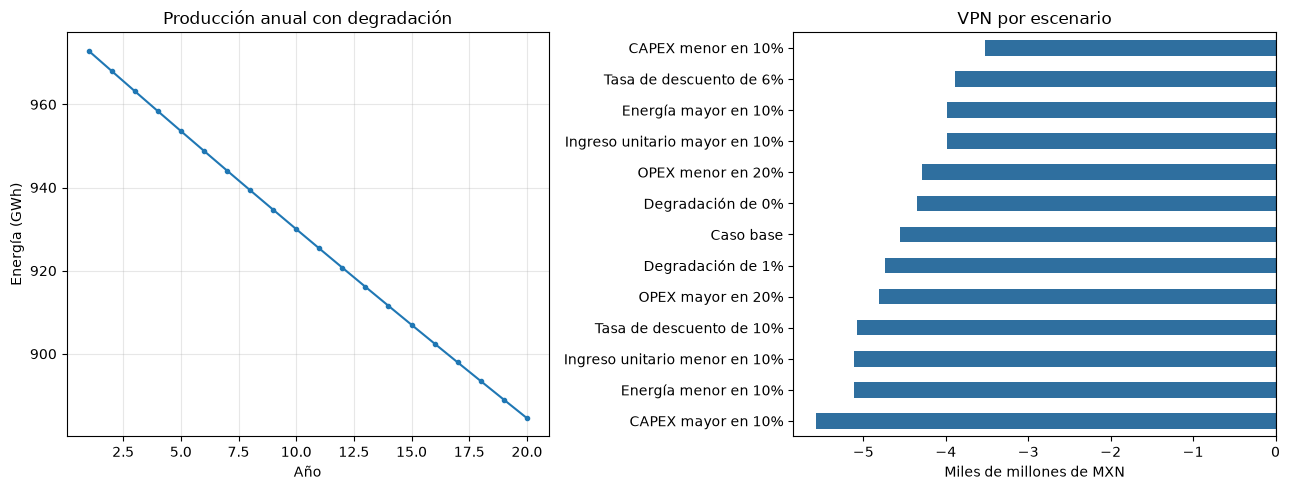

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

ejes[0].plot(anos, energia / 1_000, marker='o', markersize=3)
ejes[0].set_title('Producción anual con degradación')
ejes[0].set_xlabel('Año')
ejes[0].set_ylabel('Energía (GWh)')
ejes[0].grid(alpha=0.3)

colores = ['#2f6f9f' if valor < 0 else '#2b9348' for valor in sensibilidad['VPN (miles de millones de MXN)']]
sensibilidad['VPN (miles de millones de MXN)'].sort_values().plot.barh(ax=ejes[1], color=colores)
ejes[1].axvline(0, color='black', linewidth=0.8)
ejes[1].set_title('VPN por escenario')
ejes[1].set_xlabel('Miles de millones de MXN')
ejes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## 11. Respuesta a la pregunta central

**¿El ingreso esperado por cada unidad de energía cubre todos los costos actualizados y proporciona el rendimiento exigido al proyecto?**

No, bajo los datos y supuestos del ejercicio. El ingreso unitario implícito es aproximadamente **0.61414 MXN/kWh**, mientras que el LCOE es **1.10734 MXN/kWh**. Los ingresos cubren alrededor del **55.46%** del costo actualizado y el VPN es **−4,549.62 millones de MXN**.

Esta conclusión corresponde al modelo académico. No constituye una valoración del desempeño financiero real del Parque Solar Villanueva.

# Actividad para el estudiante

En esta sección no es necesario programar ni modificar las fórmulas del modelo. Ejecute las celdas en orden, analice los resultados y escriba sus respuestas únicamente en las celdas de texto indicadas.

Para el escenario propio deberá modificar solamente los valores ubicados entre las líneas `INICIO DE VALORES EDITABLES` y `FIN DE VALORES EDITABLES`.

## A. Comprobación del caso base

Ejecute la celda siguiente. La tabla reúne automáticamente los resultados principales calculados anteriormente.

In [13]:
resumen_caso_base = pd.DataFrame(
    {
        "Indicador": [
            "Factor de planta",
            "Energía del año 20 (MWh)",
            "Valor presente de la energía (MWh)",
            "Valor presente de los costos (MXN)",
            "LCOE (MXN/kWh)",
            "Ingreso unitario implícito (MXN/kWh)",
            "VPN (MXN)",
            "Porcentaje de costos cubierto",
        ],
        "Resultado": [
            f"{factor_planta:.2%}",
            f"{energia[-1]:,.2f}",
            f"{vp_energia:,.2f}",
            f"{vp_costos:,.2f}",
            f"{lcoe_mxn_kwh:.5f}",
            f"{ingreso_unitario_mxn_kwh:.5f}",
            f"{vpn:,.2f}",
            f"{cobertura_costos:.2%}",
        ],
    }
)

display(resumen_caso_base)

,Indicador,Resultado
0,Factor de planta,30.60%
1,Energía del año 20 (MWh),"884,531.76"
2,Valor presente de la energía (MWh),"9,224,578.46"
3,Valor presente de los costos (MXN),"10,214,772,487.04"
4,LCOE (MXN/kWh),1.10734
5,Ingreso unitario implícito (MXN/kWh),0.61414
6,VPN (MXN),"-4,549,615,206.72"
7,Porcentaje de costos cubierto,55.46%


### Interpretación del caso base

Sustituya los textos entre corchetes por sus respuestas.

1. ¿El ingreso unitario es mayor o menor que el LCOE?  
   **Respuesta:** [Escriba aquí]

2. ¿El VPN es positivo o negativo y qué significa?  
   **Respuesta:** [Escriba aquí]

3. ¿El proyecto satisface el rendimiento exigido en el modelo?  
   **Respuesta:** [Escriba aquí]

## B. Escenarios obligatorios

Los cinco escenarios ya están programados. Ejecute la celda para obtener la comparación. No modifique el código.

In [14]:
escenarios_actividad = {
    "Caso base": {},
    "Tasa de descuento de 6%": {"tasa": 0.06},
    "CAPEX 10% menor": {"factor_capex": 0.90},
    "Energía 10% mayor": {"factor_energia": 1.10},
    "Ingreso unitario 20% mayor": {"factor_ingreso": 1.20},
    "OPEX 20% menor": {"factor_opex": 0.80},
}

filas_actividad = []
for nombre, parametros in escenarios_actividad.items():
    lcoe_escenario, vpn_escenario = evaluar_escenario(**parametros)
    filas_actividad.append(
        {
            "Escenario": nombre,
            "LCOE (MXN/kWh)": lcoe_escenario,
            "VPN (millones de MXN)": vpn_escenario / 1e6,
            "¿VPN positivo?": "Sí" if vpn_escenario >= 0 else "No",
        }
    )

tabla_actividad = pd.DataFrame(filas_actividad).set_index("Escenario")
display(tabla_actividad.round(3))

,LCOE (MXN/kWh),VPN (millones de MXN),¿VPN positivo?
Escenario,,,
Caso base,1.11,"-4,549.61",No
Tasa de descuento de 6%,0.98,"-3,891.78",No
CAPEX 10% menor,1.00,"-3,528.14",No
Energía 10% mayor,1.01,"-3,983.10",No
Ingreso unitario 20% mayor,1.11,"-3,416.58",No
OPEX 20% menor,1.08,"-4,292.77",No


### Análisis comparativo

Sustituya los textos entre corchetes por sus respuestas.

1. ¿Qué escenario produce el menor LCOE?  
   **Respuesta:** [Escriba aquí]

2. ¿Qué escenario produce el mayor VPN?  
   **Respuesta:** [Escriba aquí]

3. ¿Cuál de las variables tiene mayor efecto en los resultados? Utilice los valores de la tabla para justificar su respuesta.  
   **Respuesta:** [Escriba aquí]

4. ¿Por qué aumentar el ingreso modifica el VPN, pero no modifica el LCOE?  
   **Respuesta:** [Escriba aquí]

5. ¿Reducir solamente el OPEX vuelve viable el proyecto?  
   **Respuesta:** [Escriba aquí]

6. ¿Cuál de los cambios evaluados parece más factible en un proyecto real?  
   **Respuesta:** [Escriba aquí]

## C. Escenario propio de viabilidad

El objetivo es encontrar una combinación que produzca un VPN mayor o igual que cero. Modifique únicamente los seis valores señalados en la celda. Puede ejecutarla varias veces hasta encontrar un escenario satisfactorio.

Interpretación de los factores:

- `0.90` representa una reducción de 10%.
- `1.10` representa un aumento de 10%.
- La tasa y la degradación se escriben como decimales: `0.06` equivale a 6%.

In [15]:
# ============================================================
# INICIO DE VALORES EDITABLES
# Modifique solamente los valores numéricos de este bloque.
# ============================================================
tasa_propuesta = 0.08
factor_capex_propuesto = 1.00
factor_energia_propuesto = 1.00
factor_opex_propuesto = 1.00
factor_ingreso_propuesto = 1.00
degradacion_propuesta = 0.005
# ============================================================
# FIN DE VALORES EDITABLES
# No modifique el código situado debajo de esta línea.
# ============================================================

lcoe_propuesto, vpn_propuesto = evaluar_escenario(
    tasa=tasa_propuesta,
    factor_capex=factor_capex_propuesto,
    factor_energia=factor_energia_propuesto,
    factor_opex=factor_opex_propuesto,
    factor_ingreso=factor_ingreso_propuesto,
    degradacion_anual=degradacion_propuesta,
)

comparacion_propuesta = pd.DataFrame(
    {
        "Indicador": ["LCOE (MXN/kWh)", "VPN (millones de MXN)"],
        "Caso base": [lcoe_mxn_kwh, vpn / 1e6],
        "Escenario propuesto": [lcoe_propuesto, vpn_propuesto / 1e6],
    }
).set_index("Indicador")

display(comparacion_propuesta.round(3))

if vpn_propuesto >= 0:
    print("El escenario propuesto alcanza un VPN mayor o igual que cero.")
else:
    print("El escenario todavía no alcanza la viabilidad. Modifique los valores editables y ejecute nuevamente.")

,Caso base,Escenario propuesto
Indicador,,
LCOE (MXN/kWh),1.11,1.11
VPN (millones de MXN),"-4,549.61","-4,549.61"


El escenario todavía no alcanza la viabilidad. Modifique los valores editables y ejecute nuevamente.


### Justificación del escenario propio

Sustituya los textos entre corchetes por sus respuestas.

1. ¿Qué variables modificó y en qué porcentaje?  
   **Respuesta:** [Escriba aquí]

2. ¿Cuál fue el LCOE obtenido?  
   **Respuesta:** [Escriba aquí]

3. ¿Cuál fue el VPN obtenido?  
   **Respuesta:** [Escriba aquí]

4. ¿Qué combinación permitió alcanzar o acercarse a la viabilidad?  
   **Respuesta:** [Escriba aquí]

5. ¿Los cambios propuestos parecen técnicamente y económicamente razonables? Explique.  
   **Respuesta:** [Escriba aquí]

## D. Conclusión individual

Escriba una conclusión de entre 200 y 300 palabras que responda:

> ¿Qué tendría que cambiar para que el proyecto sea económicamente viable bajo el modelo utilizado?

La conclusión debe comparar el caso base con el escenario propio, mencionar el LCOE y el VPN, identificar las variables de mayor influencia y aclarar que los resultados pertenecen a un modelo académico.

**Conclusión:**  
[Escriba aquí]

## E. Revisión antes de entregar

- [ ] Ejecuté todas las celdas en orden.
- [ ] El cuaderno no muestra errores.
- [ ] Respondí las preguntas del caso base.
- [ ] Analicé los escenarios obligatorios.
- [ ] Construí y justifiqué un escenario propio.
- [ ] Escribí la conclusión individual.
- [ ] Guardé el archivo como `Apellido_Nombre_Actividad_1.ipynb`.

## Referencias

1. Proyectos México. *0576 CENACE: 1a Subasta Eléctrica de Largo Plazo (SLP-1/2015), Parque Solar Villanueva*. https://www.proyectosmexico.gob.mx/proyecto_inversion/576-cenace-subasta-electrica-de-largo-plazo-parque-solar-villanueva/
2. Secretaría de Energía. *Se inaugura la Planta Solar Villanueva en Coahuila*. https://www.gob.mx/sener/es/articulos/se-inaugura-la-planta-solar-villanueva-en-coahuila
3. National Renewable Energy Laboratory. *LCOE Calculator — System Advisor Model*. https://sam.nlr.gov/financial-models/lcoe-calculator.html